<a href="https://colab.research.google.com/github/Ewanjohndennis/ML_LAB/blob/main/assignment13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 13 — Week 3 October

## Learning Objective

Learn ensemble learning techniques, including Random Forest, Bagging, AdaBoost, Gradient Boosting, and XGBoost.

## Experiment 1: Comparison of Linear Regression and Random Forest Regression

### Problem Statement

A real estate company wants to predict house prices based on area, number of bedrooms, house age, and distance from the city centre. The objective is to compare Linear Regression and Random Forest Regression in predicting house prices.

### Tasks

1. Create a Pandas DataFrame using the given house dataset.
2. Separate the independent variables (area, bedrooms, age, and distance) from the target variable (house price).
3. Split the dataset into 80% training data and 20% testing data using a fixed random state.
4. Implement a Linear Regression model and predict house prices.
5. Implement a Random Forest Regression model using 100 decision trees.
6. Evaluate both models using MAE, MSE, RMSE, and R² score.
7. Display a comparison table containing actual prices and predictions from both models.
8. Plot actual house prices versus predicted prices.
9. Compare the performance of both models.
10. Predict the price of a new house with an area of 1600 sq. ft., 3 bedrooms, age of 5 years, and distance of 4 km.
11. Change the number of Random Forest trees to 10, 50, 100, and 200, and compare the evaluation metrics.
12. Explain why Linear Regression may perform poorly when the relationship between features and house price is nonlinear.
13. Explain how Random Forest Regression combines predictions from multiple decision trees.
14. Discuss why a very small dataset may not provide a reliable comparison between the two models.


Model Evaluation:
  Metric  Linear Regression  Random Forest
     MAE              3.397          4.430
     MSE             16.899         23.549
    RMSE              4.111          4.853
R2 Score              0.961          0.945

Predictions:
 Actual Price  Linear Regression  Random Forest
           75              74.16          68.10
           42              48.45          44.05
           25              22.10          29.34


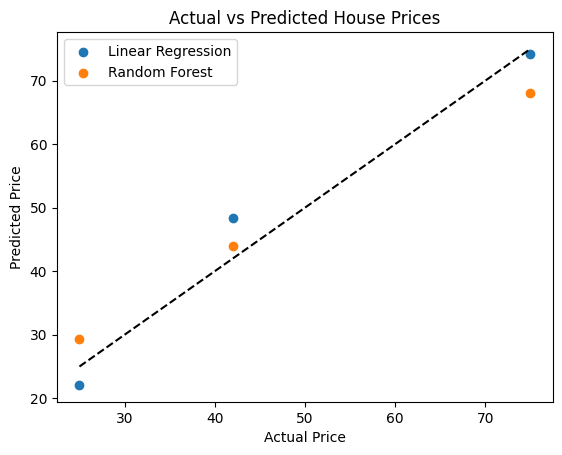

New House Price - Linear Regression: 52.82239303195583
New House Price - Random Forest: 49.58

Number of Trees: 10
MAE: 5.833333333333333
MSE: 36.91000000000001
RMSE: 6.075360071633615
R2 Score: 0.9143398659102631

Number of Trees: 50
MAE: 4.686666666666668
MSE: 24.484933333333355
RMSE: 4.948225271077839
R2 Score: 0.9431757607013924

Number of Trees: 100
MAE: 4.430000000000001
MSE: 23.549366666666685
RMSE: 4.852768969018275
R2 Score: 0.9453470087674058

Number of Trees: 200
MAE: 4.503333333333331
MSE: 24.480166666666644
RMSE: 4.947743593464262
R2 Score: 0.9431868231046932


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.DataFrame({
    'Area': [800, 900, 1000, 1200, 1400, 1500, 1700, 1800, 2000, 2200, 1100, 1600, 1900, 1300, 2100],
    'Bedrooms': [2, 2, 2, 3, 3, 3, 3, 4, 4, 4, 2, 3, 4, 3, 4],
    'Age': [15, 12, 10, 8, 6, 5, 4, 3, 2, 1, 20, 15, 10, 12, 5],
    'Distance': [8, 7, 6, 5, 4, 4, 3, 3, 2, 2, 9, 7, 5, 6, 3],
    'Price': [25, 28, 32, 38, 45, 48, 55, 60, 68, 75, 30, 42, 58, 40, 72]
})

X = df[['Area', 'Bedrooms', 'Age', 'Distance']]
y = df['Price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

def evaluate(y_test, pred):
    return [
        mean_absolute_error(y_test, pred),
        mean_squared_error(y_test, pred),
        np.sqrt(mean_squared_error(y_test, pred)),
        r2_score(y_test, pred)
    ]

results = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2 Score'],
    'Linear Regression': evaluate(y_test, lr_pred),
    'Random Forest': evaluate(y_test, rf_pred)
})

print("Model Evaluation:")
print(results.round(3).to_string(index=False))

comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Linear Regression': lr_pred,
    'Random Forest': rf_pred
})

print("\nPredictions:")
print(comparison.round(2).to_string(index=False))

plt.scatter(y_test, lr_pred, label='Linear Regression')
plt.scatter(y_test, rf_pred, label='Random Forest')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--')
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.show()

new_house = pd.DataFrame({
    'Area': [1600],
    'Bedrooms': [3],
    'Age': [5],
    'Distance': [4]
})

print("New House Price - Linear Regression:", lr.predict(new_house)[0])
print("New House Price - Random Forest:", rf.predict(new_house)[0])

for n in [10, 50, 100, 200]:
    model = RandomForestRegressor(n_estimators=n, random_state=42)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print("\nNumber of Trees:", n)
    print("MAE:", mean_absolute_error(y_test, pred))
    print("MSE:", mean_squared_error(y_test, pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
    print("R2 Score:", r2_score(y_test, pred))

## Experiment 2: Implementation of Bagging Using Random Forest on the Titanic Dataset

### Problem Statement

The Titanic dataset contains information about passengers, including age, gender, passenger class, fare, and survival status. The objective is to predict passenger survival using a Bagging Classifier and compare its performance with a single Decision Tree classifier.

### Dataset Features

* `pclass`: Passenger class
* `sex`: Gender
* `age`: Age of the passenger
* `sibsp`: Number of siblings or spouses aboard
* `parch`: Number of parents or children aboard
* `fare`: Ticket fare
* `embarked`: Port of embarkation
* `survived`: Target variable (0 = Did not survive, 1 = Survived)

### Tasks

1. Load the Titanic dataset into a Pandas DataFrame.
2. Select the input features and target variable.
3. Handle missing values in the age and embarked columns.
4. Convert categorical features into numerical representations.
5. Split the dataset into training and testing sets using an 80:20 ratio.
6. Build a Decision Tree classifier as the baseline model.
7. Implement a Bagging Classifier using 100 decision tree estimators.
8. Evaluate both models using accuracy, precision, recall, F1-score, and confusion matrix.
9. Compare the models using a bar chart.
10. Discuss how bootstrap sampling and aggregation improve model stability and generalization.


   Metric  Decision Tree  Bagging
 Accuracy          0.827    0.810
Precision          0.806    0.769
   Recall          0.725    0.725
 F1-Score          0.763    0.746

Decision Tree Confusion Matrix:
[[98 12]
 [19 50]]

Bagging Confusion Matrix:
[[95 15]
 [19 50]]


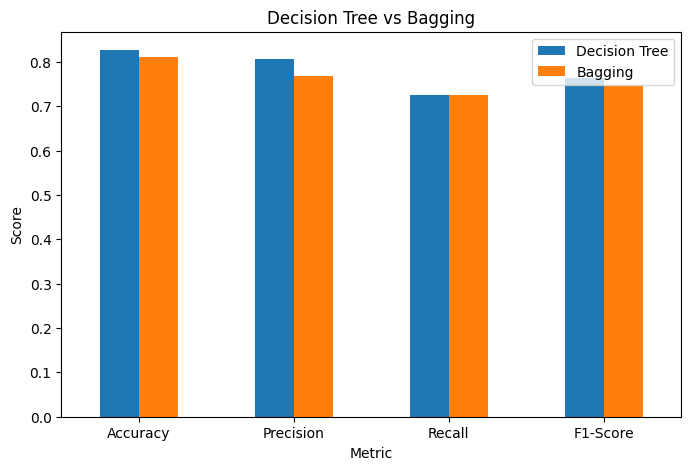

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

df = sns.load_dataset('titanic')

X = df[['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']]
y = df['survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

numeric = ['pclass', 'age', 'sibsp', 'parch', 'fare']
categorical = ['sex', 'embarked']

preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), numeric),
    ('cat', make_pipeline(
        SimpleImputer(strategy='most_frequent'),
        OneHotEncoder(handle_unknown='ignore')
    ), categorical)
])

tree = make_pipeline(
    preprocessor,
    DecisionTreeClassifier(random_state=42)
)

bagging = make_pipeline(
    preprocessor,
    BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=100,
        random_state=42
    )
)

tree.fit(X_train, y_train)
bagging.fit(X_train, y_train)

pred_tree = tree.predict(X_test)
pred_bagging = bagging.predict(X_test)

def metrics(y, pred):
    return [
        accuracy_score(y, pred),
        precision_score(y, pred, zero_division=0),
        recall_score(y, pred, zero_division=0),
        f1_score(y, pred, zero_division=0)
    ]

results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Decision Tree': metrics(y_test, pred_tree),
    'Bagging': metrics(y_test, pred_bagging)
})

print(results.round(3).to_string(index=False))

print("\nDecision Tree Confusion Matrix:")
print(confusion_matrix(y_test, pred_tree))

print("\nBagging Confusion Matrix:")
print(confusion_matrix(y_test, pred_bagging))

results.set_index('Metric').plot(kind='bar', figsize=(8, 5))
plt.title("Decision Tree vs Bagging")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.show()

## Experiment 3: Ensemble Boosting Techniques Using the Titanic Dataset

### Problem Statement

The objective is to implement and compare three boosting algorithms—AdaBoost, Gradient Boosting, and XGBoost—to predict passenger survival using the Titanic dataset.

### Tasks

1. Implement AdaBoost to predict passenger survival.
2. Implement Gradient Boosting for passenger survival prediction.
3. Implement XGBoost for passenger survival prediction.
4. Use the same dataset and train-test split for a fair comparison.
5. Use a fixed random state to ensure reproducibility.
6. Evaluate all three models using accuracy, precision, recall, and F1-score.
7. Display the evaluation metrics in a comparison table.
8. Plot a bar chart comparing the performance of all three models.
9. Identify the best-performing model on the test set and explain why the results may differ.


            Model  Accuracy  Precision  Recall  F1-Score
         AdaBoost     0.782      0.750   0.652     0.698
Gradient Boosting     0.799      0.789   0.652     0.714
          XGBoost     0.799      0.746   0.725     0.735


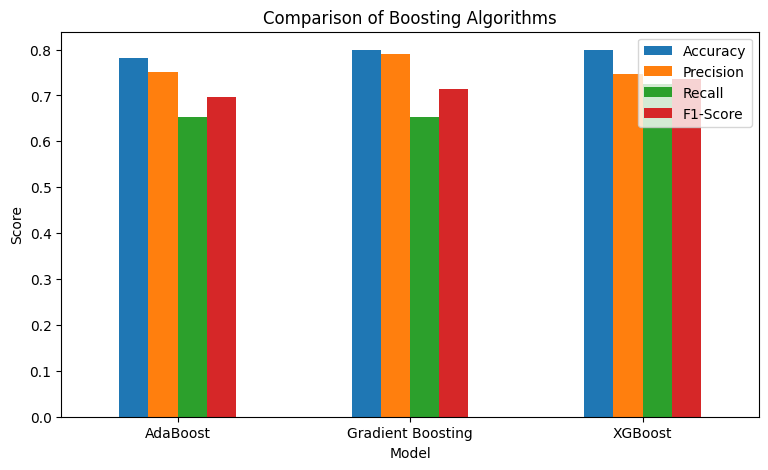


Best Model by Accuracy:
Gradient Boosting


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

df = sns.load_dataset('titanic')

X = df[['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']]
y = df['survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

numeric = ['pclass', 'age', 'sibsp', 'parch', 'fare']
categorical = ['sex', 'embarked']

preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), numeric),
    ('cat', make_pipeline(
        SimpleImputer(strategy='most_frequent'),
        OneHotEncoder(handle_unknown='ignore')
    ), categorical)
])

models = {
    'AdaBoost': AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        n_estimators=100,
        random_state=42
    ),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

try:
    from xgboost import XGBClassifier

    models['XGBoost'] = XGBClassifier(
        n_estimators=100,
        eval_metric='logloss',
        random_state=42
    )
except ImportError:
    print("Installing XGBoost...")
    %pip -q install xgboost
    from xgboost import XGBClassifier

    models['XGBoost'] = XGBClassifier(
        n_estimators=100,
        eval_metric='logloss',
        random_state=42
    )

results = []

for name, model in models.items():
    pipeline = make_pipeline(preprocessor, model)
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)

    results.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred, zero_division=0),
        recall_score(y_test, pred, zero_division=0),
        f1_score(y_test, pred, zero_division=0)
    ])

results = pd.DataFrame(
    results,
    columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score']
)

print(results.round(3).to_string(index=False))

results.set_index('Model').plot(kind='bar', figsize=(9, 5))
plt.title("Comparison of Boosting Algorithms")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.show()

print("\nBest Model by Accuracy:")
print(results.loc[results['Accuracy'].idxmax(), 'Model'])

## Experiment 4: Comparison of Bagging and Boosting on the Titanic Dataset

### Problem Statement

Bagging and Boosting are ensemble learning techniques that combine multiple models to improve prediction performance. The objective is to implement both methods using the Titanic dataset and compare their classification performance.

### Tasks

1. Load and preprocess the Titanic dataset.
2. Implement Bagging using a Decision Tree classifier as the base estimator.
3. Implement Boosting using an algorithm such as AdaBoost.
4. Evaluate both methods using accuracy, precision, recall, and F1-score.
5. Display a comparison table of the evaluation metrics.
6. Plot a bar chart comparing the performance of both methods.
7. Discuss how Bagging and Boosting improve model performance.
8. Explain the strengths and weaknesses of each method.


   Model  Accuracy  Precision  Recall  F1-Score
 Bagging     0.810      0.769   0.725     0.746
AdaBoost     0.782      0.750   0.652     0.698


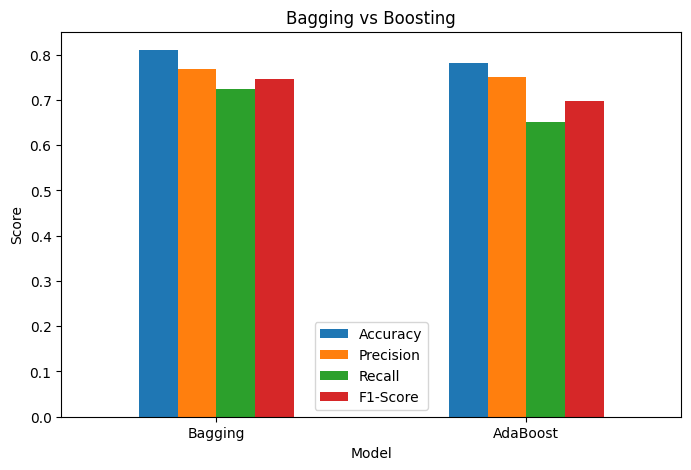

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

df = sns.load_dataset('titanic')

X = df[['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']]
y = df['survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

numeric = ['pclass', 'age', 'sibsp', 'parch', 'fare']
categorical = ['sex', 'embarked']

preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), numeric),
    ('cat', make_pipeline(
        SimpleImputer(strategy='most_frequent'),
        OneHotEncoder(handle_unknown='ignore')
    ), categorical)
])

models = {
    'Bagging': BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=100,
        random_state=42
    ),
    'AdaBoost': AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        n_estimators=100,
        random_state=42
    )
}

results = []

for name, model in models.items():
    pipeline = make_pipeline(preprocessor, model)
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)

    results.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred, zero_division=0),
        recall_score(y_test, pred, zero_division=0),
        f1_score(y_test, pred, zero_division=0)
    ])

results = pd.DataFrame(
    results,
    columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score']
)

print(results.round(3).to_string(index=False))

results.set_index('Model').plot(kind='bar', figsize=(8, 5))
plt.title("Bagging vs Boosting")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.show()